# CNN Development on Intel Image Classification Dataset

**Student ID:** 23-55291-3

**Objective:** Design and train a custom CNN that classifies natural scene images into 6 classes.

## 1. Import Libraries

 Imports the libraries for data loading (torchvision), model building (PyTorch), plotting (matplotlib), and evaluation metrics (scikit-learn).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# use the GPU if it is available, otherwise use the CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


## 2. Load and Explore Dataset

**Dataset description**

- **Name:** Intel Image Classification (Kaggle, by puneet6060)
- **Link:** https://www.kaggle.com/datasets/puneet6060/intel-image-classification
- **Task:** multi-class scene classification
- **Classes (6):** buildings, forest, glacier, mountain, sea, street
- **Images:** colour (RGB) images of size 150 x 150,  14,034 for training and 3,000 for testing
- **Folders used:** seg_train (training) and seg_test (testing). The `seg_pred` folder has no labels, so it is not used.

In [ ]:
import kagglehub
path = kagglehub.dataset_download("puneet6060/intel-image-classification")
print("Path to dataset files:", path)

train_folder = path + '/seg_train/seg_train'
test_folder = path + '/seg_test/seg_test'

# load the folders without any transform, only to explore the data
raw_train = datasets.ImageFolder(train_folder)
raw_test = datasets.ImageFolder(test_folder)
classes = raw_train.classes
print("Classes and indices:", raw_train.class_to_idx)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Path to dataset files: /kaggle/input/intel-image-classification
Classes and indices: {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


buildings  train:  2191 | test:   437
forest     train:  2271 | test:   474
glacier    train:  2404 | test:   553
mountain   train:  2512 | test:   525
sea        train:  2274 | test:   510
street     train:  2382 | test:   501


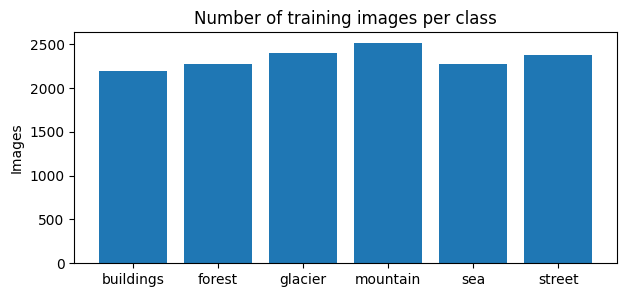

In [ ]:
# count how many images each class has
train_counts = Counter(raw_train.targets)
test_counts = Counter(raw_test.targets)

for i, name in enumerate(classes):
    print(f"{name:10s} train: {train_counts[i]:5d} | test: {test_counts[i]:5d}")

plt.figure(figsize=(7, 3))
plt.bar(classes, [train_counts[i] for i in range(len(classes))])
plt.title("Number of training images per class")
plt.ylabel("Images")
plt.show()

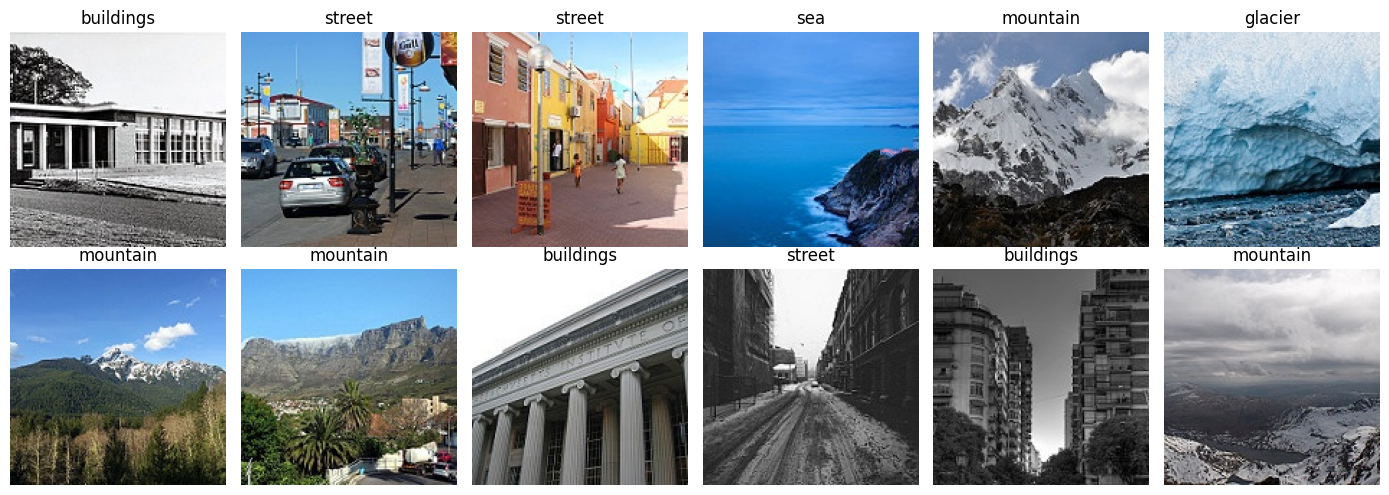

In [ ]:
# showing 12 random training images with their class names
np.random.seed(42)
random_ids = np.random.choice(len(raw_train), 12, replace=False)

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, ix in zip(axes.flat, random_ids):
    img, label = raw_train[ix]
    ax.imshow(img)
    ax.set_title(classes[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Data Preprocessing & Augmentation

- **Resize** all images to 128 x 128 so every image has the same size.
- **Normalize** pixel values to the range [-1, 1] so training is more stable.
- **Augmentation (training only):** random horizontal flip, small rotation, and small brightness/contrast change. This shows the model slightly different versions of each image, so it learns the scene and does not memorize the pictures.
- **Validation and test images** are only resized and normalized, because they must stay unchanged to give a fair score.
- **Split:** 85% of `seg_train` is used for training and 15% for validation. `seg_test` is kept untouched as the test set.

In [ ]:
size = 128

train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),                          # flip left-right
    transforms.RandomRotation(10),                              # rotate up to 10 degrees
    transforms.ColorJitter(brightness=0.2, contrast=0.2),       # small light changes
    transforms.ToTensor(),                                      # image -> tensor in [0, 1]
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])      # [0, 1] -> [-1, 1]
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

In [ ]:
# two copies of the training folder: one with augmentation, one without (for validation)
train_aug = datasets.ImageFolder(train_folder, transform=train_transform)
train_clean = datasets.ImageFolder(train_folder, transform=val_transform)
test_data = datasets.ImageFolder(test_folder, transform=val_transform)

# shuffle the indices with a fixed seed, then take 15% for validation
generator = torch.Generator().manual_seed(42)
shuffled = torch.randperm(len(train_aug), generator=generator).tolist()
val_size = int(0.15 * len(train_aug))

train_data = Subset(train_aug, shuffled[val_size:])      # augmented images
val_data = Subset(train_clean, shuffled[:val_size])      # clean images

print('Dataset Summary')
print('Train Data: ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data: ', len(test_data))

Dataset Summary
Train Data:  11929
Validation Data:  2105
Test Data:  3000


**Hyperparameters and rationale**

| Hyperparameter | Value | Reason |
|---|---|---|
| Image size | 128 x 128 | Keeps enough detail while training stays fast |
| Batch size | 32 | Balances stable updates and GPU memory |
| Learning rate | 1e-3 | A standard starting value for Adam |
| Epochs | 15 | Chosen to keep training short; validation accuracy was still improving slightly, so more epochs could help |
| Optimizer | Adam | Adjusts the step size for each weight, so it converges fast without much tuning |
| Loss | Cross-entropy | The standard loss for multi-class classification |
| Activation | ReLU | Adds non-linearity and is fast; the last layer has none because the loss applies softmax itself |
| Dropout | 0.5 | Switches off half of the features during training to reduce overfitting |

In [ ]:
batch_size = 32
learning_rate = 1e-3
epoch_number = 15

trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

## 4. CNN Architecture

The model has 4 blocks of **Conv -> BatchNorm -> ReLU -> MaxPool**, followed by a small classifier.

- **Conv2d (3x3, padding=1):** learns patterns such as edges and textures. Padding keeps the image size unchanged.
- **Channels 32 -> 64 -> 128 -> 256:** early layers find simple patterns, deeper layers combine them into complex ones (like trees, waves, or buildings), so more filters are needed.
- **BatchNorm2d:** keeps the values in a stable range, which makes training faster and steadier.
- **ReLU:** adds non-linearity so the network can learn complex patterns.
- **MaxPool2d(2):** halves the height and width, which reduces computation and keeps the strongest features.
- **Dropout(0.5) + Linear layers:** turn the features into 6 class scores. Dropout reduces overfitting.

In [ ]:
def get_model():
    model = nn.Sequential(
        # Feature extraction
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(128, 256, kernel_size=3, padding=1),
        nn.BatchNorm2d(256),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Classifier
        nn.Flatten(),
        nn.Dropout(0.5),
        nn.Linear(256 * 8 * 8, 128),
        nn.ReLU(),
        nn.Linear(128, len(classes))
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

In [ ]:
!pip install torchsummary -q
from torchsummary import summary

model, loss_fn, optimizer = get_model()
summary(model, input_size=(3, size, size));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 128, 128]             896
       BatchNorm2d-2         [-1, 32, 128, 128]              64
              ReLU-3         [-1, 32, 128, 128]               0
         MaxPool2d-4           [-1, 32, 64, 64]               0
            Conv2d-5           [-1, 64, 64, 64]          18,496
       BatchNorm2d-6           [-1, 64, 64, 64]             128
              ReLU-7           [-1, 64, 64, 64]               0
         MaxPool2d-8           [-1, 64, 32, 32]               0
            Conv2d-9          [-1, 128, 32, 32]          73,856
      BatchNorm2d-10          [-1, 128, 32, 32]             256
             ReLU-11          [-1, 128, 32, 32]               0
        MaxPool2d-12          [-1, 128, 16, 16]               0
           Conv2d-13          [-1, 256, 16, 16]         295,168
      BatchNorm2d-14          [-1, 256,

## 5. Training Loop with Validation

In every epoch the model first learns from the training data (weights are updated), then it is checked on the validation data (weights are **not** updated). The validation score shows how well the model works on images it did not train on.

In [ ]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()                   # clear old gradients
        prediction = model(x)                   # forward pass
        batch_loss = loss_fn(prediction, y)     # how wrong the model is
        batch_loss.backward()                   # find the gradients
        optimizer.step()                        # update the weights

        epoch_losses.append(batch_loss.item())
        epoch_accuracies.extend((prediction.argmax(-1) == y).tolist())
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()                                # turns off dropout, BatchNorm uses saved statistics
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        val_accuracies.extend((prediction.argmax(-1) == y).tolist())
    return np.mean(val_losses), np.mean(val_accuracies)

In [ ]:
# start with a fresh model, then train and validate for every epoch
model, loss_fn, optimizer = get_model()

train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):
    epoch_loss, epoch_accuracy = train_one_epoch(trn_dl, model, loss_fn, optimizer)
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    v_loss, v_acc = validation(val_dl, model, loss_fn)
    val_losses.append(v_loss)
    val_accuracies.append(v_acc)

    print(f"Epoch [{epoch + 1}/{epoch_number}]"
          f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
          f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/15] | Train Loss: 1.0289 | Train Accuracy: 62.03% | Val Loss: 0.7039 | Val Accuracy: 73.25%
Epoch [2/15] | Train Loss: 0.7109 | Train Accuracy: 74.17% | Val Loss: 0.7081 | Val Accuracy: 74.35%
Epoch [3/15] | Train Loss: 0.6131 | Train Accuracy: 77.51% | Val Loss: 0.5747 | Val Accuracy: 77.67%
Epoch [4/15] | Train Loss: 0.5677 | Train Accuracy: 79.57% | Val Loss: 0.5158 | Val Accuracy: 80.29%
Epoch [5/15] | Train Loss: 0.5056 | Train Accuracy: 81.34% | Val Loss: 0.4924 | Val Accuracy: 81.28%
Epoch [6/15] | Train Loss: 0.4825 | Train Accuracy: 82.98% | Val Loss: 0.4393 | Val Accuracy: 84.66%
Epoch [7/15] | Train Loss: 0.4629 | Train Accuracy: 83.33% | Val Loss: 0.4356 | Val Accuracy: 83.61%
Epoch [8/15] | Train Loss: 0.4423 | Train Accuracy: 83.97% | Val Loss: 0.4821 | Val Accuracy: 82.57%
Epoch [9/15] | Train Loss: 0.4188 | Train Accuracy: 84.89% | Val Loss: 0.4625 | Val Accuracy: 83.09%
Epoch [10/15] | Train Loss: 0.4049 | Train Accuracy: 85.57% | Val Loss: 0.4431 | Val Accura

## 6. Evaluate Model on Test Set

The trained model is tested once on seg_test, which was never used for training or validation. Besides accuracy, the report shows precision, recall and F1-score for each class, and a confusion matrix shows which classes get mixed up.

In [ ]:
test_loss, test_acc = validation(test_dl, model, loss_fn)
print(f'Test Loss : {test_loss:0.4f} , Test Accuracy: {test_acc*100:0.2f}%')

Test Loss : 0.3599 , Test Accuracy: 87.30%


In [ ]:
@torch.no_grad()
def get_predictions(data_loader, model):
    model.eval()
    true_labels, predicted_labels = [], []
    for x, y in data_loader:
        prediction = model(x.to(device)).argmax(-1).cpu()
        true_labels.extend(y.tolist())
        predicted_labels.extend(prediction.tolist())
    return np.array(true_labels), np.array(predicted_labels)

y_true, y_pred = get_predictions(test_dl, model)
print(classification_report(y_true, y_pred, target_names=classes, digits=4))

              precision    recall  f1-score   support

   buildings     0.7917    0.9130    0.8480       437
      forest     0.9766    0.9705    0.9735       474
     glacier     0.8755    0.7884    0.8297       553
    mountain     0.8488    0.8019    0.8247       525
         sea     0.8437    0.9314    0.8854       510
      street     0.9145    0.8543    0.8834       501

    accuracy                         0.8730      3000
   macro avg     0.8751    0.8766    0.8741      3000
weighted avg     0.8757    0.8730    0.8726      3000



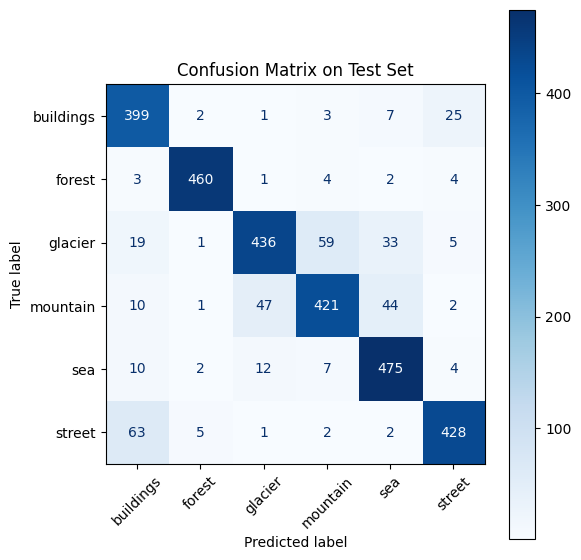

In [ ]:
# confusion matrix: rows = actual class, columns = predicted class
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap='Blues', xticks_rotation=45)
plt.title("Confusion Matrix on Test Set")
plt.tight_layout()
plt.show()

**Save the trained model weights**

Only the learned weights (state_dict) are saved. To reuse them, a new model with the same architecture is created and the weights are loaded into it. Getting the same test accuracy after reloading proves the saved file works.

In [ ]:
import os

torch.save(model.state_dict(), 'CNN_23-55291-3.pth')
print("Model size:", round(os.path.getsize('CNN_23-55291-3.pth') / (1024 * 1024), 2), "MB")

# load the weights into a new model and check the test accuracy again
saved_model = get_model()[0]
saved_model.load_state_dict(torch.load('CNN_23-55291-3.pth', map_location=device))
saved_model.eval()

reload_loss, reload_acc = validation(test_dl, saved_model, loss_fn)
print(f'Reloaded Model Test Accuracy: {reload_acc*100:0.2f}%')

Model size: 9.5 MB
Reloaded Model Test Accuracy: 87.30%


## 7. Visualizations (Loss/Accuracy Curves)

The curves show how the loss and accuracy of the training and validation data change over the epochs.

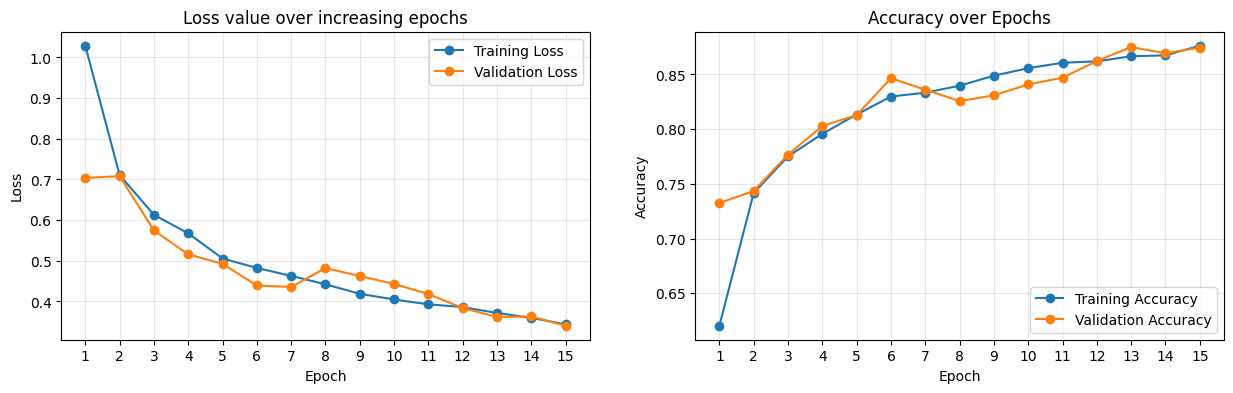

In [ ]:
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 4))

plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Explanation of the curves**

- Training loss went from 1.0289 to 0.3436, and validation loss went from 0.7039 to 0.3404.
- Training accuracy reached 87.63% and validation accuracy reached 87.46%.
- The gap is only about 0.2 points, so the model is not overfitting. Validation was often at or above training accuracy because training accuracy is measured with Dropout and augmentation active. The validation curve is slightly noisy (around epoch 8), but it follows the training curve, and both were still improving at epoch 15.

## 8. Analysis & Discussion of Results

- **Overall result:** the model reached 87.30% test accuracy on 3,000 images, close to the final validation accuracy of 87.46%, so it generalizes well to unseen images.
- **Best class:** forest (F1 0.9735).
- **Weakest class:** mountain (F1 0.8247), closely followed by glacier (0.8297).
- **confusions among the result(from the confusion matrix):** 59 glacier images were predicted as mountain and 47 mountain images as glacier. 44 mountain images were predicted as sea. 63 street images were predicted as buildings. These scenes share content (snow, rock and sky, or buildings along streets), while forest is easy because of its distinctive green texture.

## 9. Conclusions & Future Work

**Conclusion:** A custom 4-block CNN was trained on the Intel Image Classification dataset using the Adam optimizer and cross-entropy loss. It achieved 87.3% test accuracy, and the trained weights were saved and reloaded successfully.

**Future work:**
- Use transfer learning with a pretrained network (such as ResNet) for higher accuracy.
- Train for more epochs with a learning-rate scheduler and early stopping.
- stronger augmentation or a larger image size.
- Check the most confused images and look for ways to separate similar scenes such as glacier and mountain.